## read in

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_parquet("pollution_clean_long.parquet")

print(df.shape)
print(df.head())

display(df.sample(5))

print("\nMemory usage (MB)")
print("df :", round(df.memory_usage(deep=True).sum() / 1024**2, 2))


(1824216, 11)
             datetime       station   SO2    NOX    NO2     CO    RSP    O3  \
0 2013-12-30 00:00:00  Causeway Bay  13.0  401.0  188.0  113.0  121.0   2.0   
1 2013-12-30 01:00:00  Causeway Bay  11.0  251.0  142.0  116.0  115.0   9.0   
2 2013-12-30 02:00:00  Causeway Bay  11.0  234.0  130.0  107.0  104.0  12.0   
3 2013-12-30 03:00:00  Causeway Bay  10.0  188.0  115.0  107.0   94.0  13.0   
4 2013-12-30 04:00:00  Causeway Bay  10.0  173.0  110.0   85.0   97.0  22.0   

    FSP station_type  is_roadside  
0  96.0     roadside            1  
1  91.0     roadside            1  
2  81.0     roadside            1  
3  73.0     roadside            1  
4  75.0     roadside            1  


,datetime,station,SO2,NOX,NO2,CO,RSP,O3,FSP,station_type,is_roadside
1216542,2016-12-21 06:00:00,Tap Mun,11.0,13.0,12.0,71.0,24.0,56.0,14.0,general,0
1561375,2021-04-08 07:00:00,Tuen Mun,3.0,53.0,47.0,61.0,34.0,69.0,15.0,general,0
576573,2017-09-03 21:00:00,Kwun Tong,9.0,148.0,111.0,NaN,NaN,20.0,26.0,general,0
875241,2021-01-06 09:00:00,Sham Shui Po,13.0,84.0,60.0,NaN,46.0,47.0,29.0,general,0
293622,2022-08-27 06:00:00,Central/Western,3.0,7.0,6.0,NaN,7.0,40.0,3.0,general,0



Memory usage (MB)
df : 351.83


In [4]:
print(df["datetime"].min())
print(df["datetime"].max())

print()
print("Stations:", df["station"].nunique())

print()
print(df["station"].value_counts())

2013-12-30 00:00:00
2026-05-31 23:00:00

Stations: 18

station
Causeway Bay       108864
Sham Shui Po       108864
Tung Chung         108864
Tsuen Wan          108864
Tai Po             108864
Central            108864
Shatin             108864
Mong Kok           108864
Kwun Tong          108864
Kwai Chung         108864
Eastern            108864
Central/Western    108864
Yuen Long          108864
Tuen Mun           108816
Tap Mun            107376
Tseung Kwan O       89496
North               51648
Southern            51648
Name: count, dtype: int64


In [5]:
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["hour"] = df["datetime"].dt.hour

season_map = {
    12:"Winter",1:"Winter",2:"Winter",
    3:"Spring",4:"Spring",5:"Spring",
    6:"Summer",7:"Summer",8:"Summer",
    9:"Autumn",10:"Autumn",11:"Autumn"
}

df["season"] = df["month"].map(season_map)

In [6]:
pollutants = [
    "SO2",
    "NOX",
    "NO2",
    "CO",
    "RSP",
    "O3",
    "FSP"
]

df[pollutants].describe().T

,count,mean,std,min,25%,50%,75%,max
SO2,1774790.0,5.785530,5.680231,0.0,3.0,5.0,7.0,301.0
NOX,1657165.0,79.622055,88.105487,0.0,25.0,51.0,98.0,1835.0
NO2,1772781.0,44.338834,33.014330,0.0,21.0,37.0,59.0,496.0
CO,1031706.0,62.257573,26.244299,0.0,44.0,59.0,78.0,359.0
RSP,1764757.0,31.041362,21.193655,0.0,16.0,26.0,41.0,402.0
O3,1774892.0,49.237208,37.878408,0.0,19.0,41.0,72.0,434.0
FSP,1762835.0,19.222803,14.100389,0.0,9.0,16.0,25.0,296.0


## Some anaylsis

In [7]:
#Analysis 1: Dataset Overview
pollutants = [
    "SO2",
    "NOX",
    "NO2",
    "CO",
    "RSP",
    "O3",
    "FSP"
]

df[pollutants].describe().T

,count,mean,std,min,25%,50%,75%,max
SO2,1774790.0,5.785530,5.680231,0.0,3.0,5.0,7.0,301.0
NOX,1657165.0,79.622055,88.105487,0.0,25.0,51.0,98.0,1835.0
NO2,1772781.0,44.338834,33.014330,0.0,21.0,37.0,59.0,496.0
CO,1031706.0,62.257573,26.244299,0.0,44.0,59.0,78.0,359.0
RSP,1764757.0,31.041362,21.193655,0.0,16.0,26.0,41.0,402.0
O3,1774892.0,49.237208,37.878408,0.0,19.0,41.0,72.0,434.0
FSP,1762835.0,19.222803,14.100389,0.0,9.0,16.0,25.0,296.0


In [8]:
#Analysis 2: Missing Data
missing = (
    df[pollutants]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing

CO     43.443868
NOX     9.157413
FSP     3.364788
RSP     3.259428
NO2     2.819567
SO2     2.709438
O3      2.703846
dtype: float64

In [9]:
#Analysis 3: Station Comparison
station_avg = (
    df.groupby("station")[pollutants]
    .mean()
    .round(2)
)

station_avg

,SO2,NOX,NO2,CO,RSP,O3,FSP
station,,,,,,,
Causeway Bay,6.28,217.54,80.15,70.67,42.58,26.26,27.55
Central,5.99,169.08,74.95,72.79,33.20,30.22,20.88
Central/Western,5.79,49.16,36.66,NaN,29.72,56.86,18.88
Eastern,2.97,NaN,37.96,NaN,29.11,60.03,17.31
Kwai Chung,8.92,94.38,53.62,NaN,29.37,41.81,18.95
Kwun Tong,5.63,76.21,46.65,NaN,33.90,48.80,19.57
Mong Kok,5.07,162.09,76.38,75.20,33.55,28.93,22.04
North,3.01,43.29,31.56,48.89,25.83,59.42,15.40
Sham Shui Po,7.03,75.13,50.06,NaN,30.56,45.33,18.81


In [10]:
#Analysis 4: Roadside vs General
roadside_avg = (
    df.groupby("station_type")[pollutants]
    .mean()
    .round(2)
)

roadside_avg


,SO2,NOX,NO2,CO,RSP,O3,FSP
station_type,,,,,,,
general,5.79,55.08,37.16,57.52,29.87,53.80,18.29
roadside,5.78,182.86,77.16,72.90,36.44,28.48,23.50


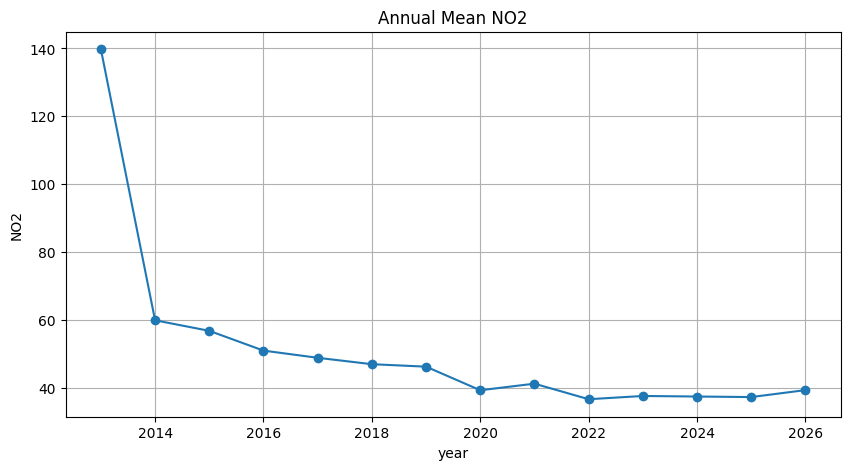

In [11]:
#Analysis 5: Long-Term Trend
yearly = (
    df.groupby("year")["NO2"]
    .mean()
)

yearly.plot(
    marker="o",
    figsize=(10,5)
)

plt.title("Annual Mean NO2")
plt.ylabel("NO2")
plt.grid(True)
plt.show()


In [12]:
#Analysis 6: Seasonal Pattern
season_order = [
    "Spring",
    "Summer",
    "Autumn",
    "Winter"
]

seasonal = (
    df.groupby("season")[pollutants]
    .mean()
    .loc[season_order]
)

seasonal

,SO2,NOX,NO2,CO,RSP,O3,FSP
season,,,,,,,
Spring,5.580577,78.689550,43.842506,61.389395,30.605256,52.223986,18.605645
Summer,5.858848,77.563435,37.320567,51.610655,18.882017,33.210249,11.289523
Autumn,5.600181,72.128382,44.141816,61.267166,32.670632,60.489127,20.051494
Winter,6.108373,89.806563,51.859489,74.517265,41.694896,50.819717,26.741145


In [13]:
#Analysis 7: Hourly Pattern

hourly = (
    df.groupby("hour")[pollutants]
    .mean()
)

hourly.head()

,SO2,NOX,NO2,CO,RSP,O3,FSP
hour,,,,,,,
0,5.365858,65.498437,39.011403,61.690329,29.612089,44.736247,18.461058
1,5.223764,48.474025,31.236098,59.192950,28.481753,48.051821,17.661297
2,5.140397,41.327796,27.173323,57.614603,27.528763,49.277596,17.092044
3,5.498596,37.536205,24.974740,55.833894,26.942093,49.295887,16.773279
4,5.087020,36.999487,24.749053,55.904796,26.593313,48.145318,16.629454


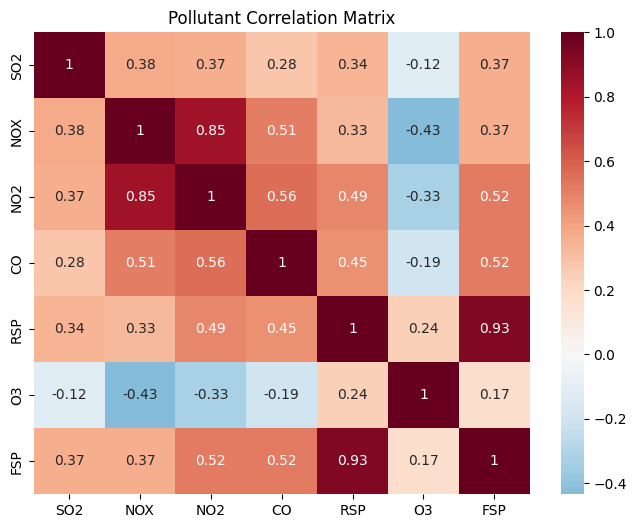

In [14]:
#Analysis 8: Correlation Matrix

corr = df[pollutants].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="RdBu_r",
    center=0
)

plt.title("Pollutant Correlation Matrix")
plt.show()


## paralle

Stations found: 18
Benchmarking with 1 workers...
Runtime = 12.126s
Benchmarking with 2 workers...
Runtime = 7.473s
Benchmarking with 4 workers...
Runtime = 3.731s
Benchmarking with 8 workers...
Runtime = 3.350s

Benchmark Results:


,Workers,Runtime (s),Speedup
0,1,12.125621,1.000000
1,2,7.472889,1.622615
2,4,3.731267,3.249733
3,8,3.350145,3.619432


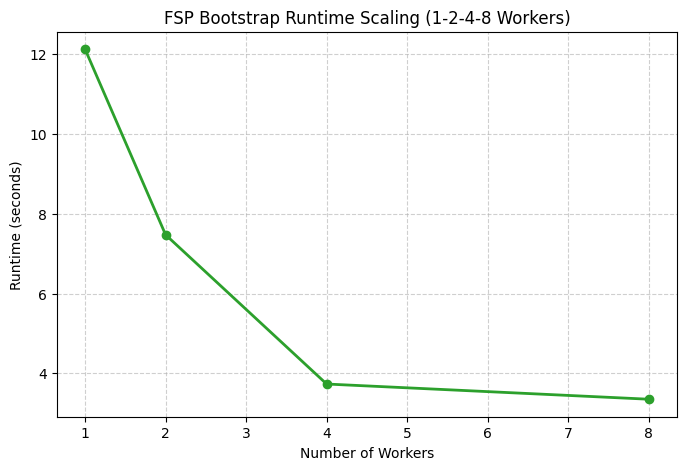

In [16]:
#1-2-4-8 Worker Benchmark (Computational View)
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

# ============================================================
# Load Pollution Dataset
# ============================================================

df = pd.read_parquet("pollution_clean_long.parquet")

df_clean = df.dropna(subset=["station", "FSP"]).copy()

stations = sorted(df_clean["station"].unique())

print(f"Stations found: {len(stations)}")

# ============================================================
# Bootstrap Function
# ============================================================

def bootstrap_station_fsp(station_name, data, n_boot=1000):

    vals = data.loc[
        data["station"] == station_name,
        "FSP"
    ].values

    if len(vals) == 0:
        return station_name, np.nan

    rng = np.random.default_rng(42)

    boot_means = [
        rng.choice(
            vals,
            size=len(vals),
            replace=True
        ).mean()
        for _ in range(n_boot)
    ]

    return station_name, np.mean(boot_means)

# ============================================================
# Runtime Benchmark
# ============================================================

worker_configs = [1, 2, 4, 8]
runtimes = []

for w in worker_configs:

    print(f"Benchmarking with {w} workers...")

    start = time.perf_counter()

    _ = Parallel(n_jobs=w)(
        delayed(bootstrap_station_fsp)(
            st,
            df_clean
        )
        for st in stations
    )

    elapsed = time.perf_counter() - start

    runtimes.append(elapsed)

    print(f"Runtime = {elapsed:.3f}s")

# ============================================================
# Results Table
# ============================================================

benchmark_df = pd.DataFrame({
    "Workers": worker_configs,
    "Runtime (s)": runtimes
})

seq_time = benchmark_df.loc[
    benchmark_df["Workers"] == 1,
    "Runtime (s)"
].iloc[0]

benchmark_df["Speedup"] = (
    seq_time /
    benchmark_df["Runtime (s)"]
)

print("\nBenchmark Results:")
display(benchmark_df)

# ============================================================
# Scaling Figure
# ============================================================

plt.figure(figsize=(8,5))

plt.plot(
    benchmark_df["Workers"],
    benchmark_df["Runtime (s)"],
    marker="o",
    linewidth=2,
    color="tab:green"
)

plt.title(
    "FSP Bootstrap Runtime Scaling (1-2-4-8 Workers)"
)

plt.xlabel("Number of Workers")
plt.ylabel("Runtime (seconds)")
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

Completed in 2.869s

Top 10 Stations


,Station,Mean_FSP,CI_Lower,CI_Upper
0,Causeway Bay,27.549034,27.453191,27.648825
1,Tuen Mun,23.142688,23.041060,23.241695
2,Mong Kok,22.041566,21.956090,22.128396
3,Central,20.881923,20.794326,20.966521
4,Yuen Long,20.557971,20.462433,20.655619
5,Kwun Tong,19.566974,19.482918,19.651306
6,Kwai Chung,18.953673,18.878171,19.033538
7,Central/Western,18.884246,18.795869,18.971467
8,Sham Shui Po,18.808246,18.726532,18.883413
9,Tsuen Wan,18.662628,18.574798,18.748972


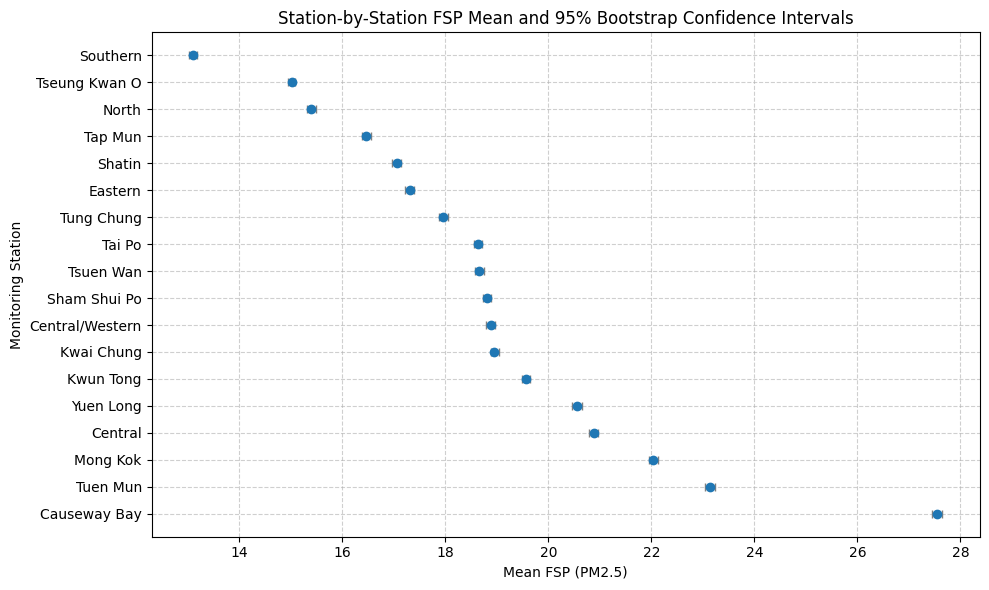

In [17]:
#Station Bootstrap with 95% CIs (Statistical View)

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

# ============================================================
# Bootstrap Function
# ============================================================

def bootstrap_station_fsp_ci(
    station_name,
    data,
    n_boot=1000
):

    vals = data.loc[
        data["station"] == station_name,
        "FSP"
    ].values

    if len(vals) == 0:
        return (
            station_name,
            np.nan,
            np.nan,
            np.nan
        )

    rng = np.random.default_rng(42)

    boot_means = [
        rng.choice(
            vals,
            size=len(vals),
            replace=True
        ).mean()
        for _ in range(n_boot)
    ]

    mean_val = np.mean(boot_means)

    ci_lower = np.percentile(
        boot_means,
        2.5
    )

    ci_upper = np.percentile(
        boot_means,
        97.5
    )

    return (
        station_name,
        mean_val,
        ci_lower,
        ci_upper
    )

# ============================================================
# Parallel Bootstrap
# ============================================================

start = time.perf_counter()

results = Parallel(n_jobs=-1)(
    delayed(
        bootstrap_station_fsp_ci
    )(
        st,
        df_clean
    )
    for st in stations
)

elapsed = time.perf_counter() - start

print(
    f"Completed in {elapsed:.3f}s"
)

# ============================================================
# Summary Table
# ============================================================

station_boot_df = pd.DataFrame(
    results,
    columns=[
        "Station",
        "Mean_FSP",
        "CI_Lower",
        "CI_Upper"
    ]
)

station_boot_df = station_boot_df.sort_values(
    "Mean_FSP",
    ascending=False
).reset_index(drop=True)

print("\nTop 10 Stations")

display(
    station_boot_df.head(10)
)

# ============================================================
# Confidence Interval Plot
# ============================================================

plt.figure(figsize=(10,6))

plt.errorbar(
    station_boot_df["Mean_FSP"],
    station_boot_df["Station"],
    xerr=[
        station_boot_df["Mean_FSP"]
        -
        station_boot_df["CI_Lower"],

        station_boot_df["CI_Upper"]
        -
        station_boot_df["Mean_FSP"]
    ],
    fmt="o",
    color="tab:blue",
    ecolor="gray",
    capsize=3
)

plt.title(
    "Station-by-Station FSP Mean and 95% Bootstrap Confidence Intervals"
)

plt.xlabel("Mean FSP (PM2.5)")
plt.ylabel("Monitoring Station")

plt.grid(
    True,
    linestyle="--",
    alpha=0.6
)

plt.tight_layout()

plt.show()

Raw station feature matrix:


,SO2,NOX,NO2,CO,RSP,O3,FSP
station,,,,,,,
Causeway Bay,6.281647,217.541139,80.153260,70.671120,42.578963,26.262917,27.549951
Central,5.985511,169.084894,74.954093,72.790286,33.204362,30.219289,20.882171
Central/Western,5.792498,49.164275,36.657908,NaN,29.720470,56.858363,18.883533
Eastern,2.967065,NaN,37.963573,NaN,29.107080,60.031791,17.307810
Kwai Chung,8.922848,94.384458,53.620935,NaN,29.366549,41.813135,18.954907
Kwun Tong,5.628653,76.213109,46.654202,NaN,33.898728,48.803616,19.567052
Mong Kok,5.068903,162.092379,76.377432,75.201733,33.552980,28.929323,22.041664
North,3.010480,43.289875,31.560098,48.889251,25.833021,59.416839,15.395143
Sham Shui Po,7.033573,75.129972,50.058279,NaN,30.557242,45.326688,18.806108



Missing values per pollutant:
SO2    0
NOX    1
NO2    0
CO     7
RSP    0
O3     0
FSP    0
dtype: int64

Missing rate:
SO2    0.000000
NOX    0.055556
NO2    0.000000
CO     0.388889
RSP    0.000000
O3     0.000000
FSP    0.000000
dtype: float64

Columns kept:
['SO2', 'NOX', 'NO2', 'RSP', 'O3', 'FSP']

Remaining missing values:
0


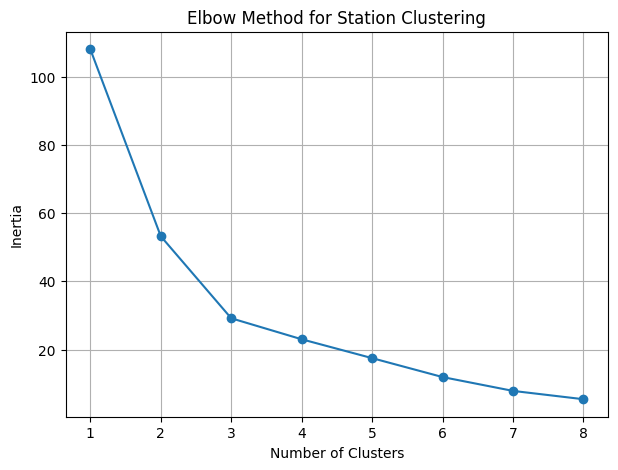


Station clusters:


,SO2,NOX,NO2,RSP,O3,FSP,cluster
station,,,,,,,
Causeway Bay,6.281647,217.541139,80.153260,42.578963,26.262917,27.549951,0
Central,5.985511,169.084894,74.954093,33.204362,30.219289,20.882171,0
Mong Kok,5.068903,162.092379,76.377432,33.552980,28.929323,22.041664,0
Eastern,2.967065,76.316280,37.963573,29.107080,60.031791,17.307810,1
Tseung Kwan O,4.472002,35.113707,24.826357,26.324104,66.923281,15.017811,1
North,3.010480,43.289875,31.560098,25.833021,59.416839,15.395143,1
Tap Mun,5.843017,12.187160,9.240420,27.910814,74.345621,16.468567,1
Shatin,5.880729,44.520320,32.613417,27.236788,56.353681,17.059384,1
Southern,3.747551,34.551449,25.928424,24.643624,65.776622,13.104643,1


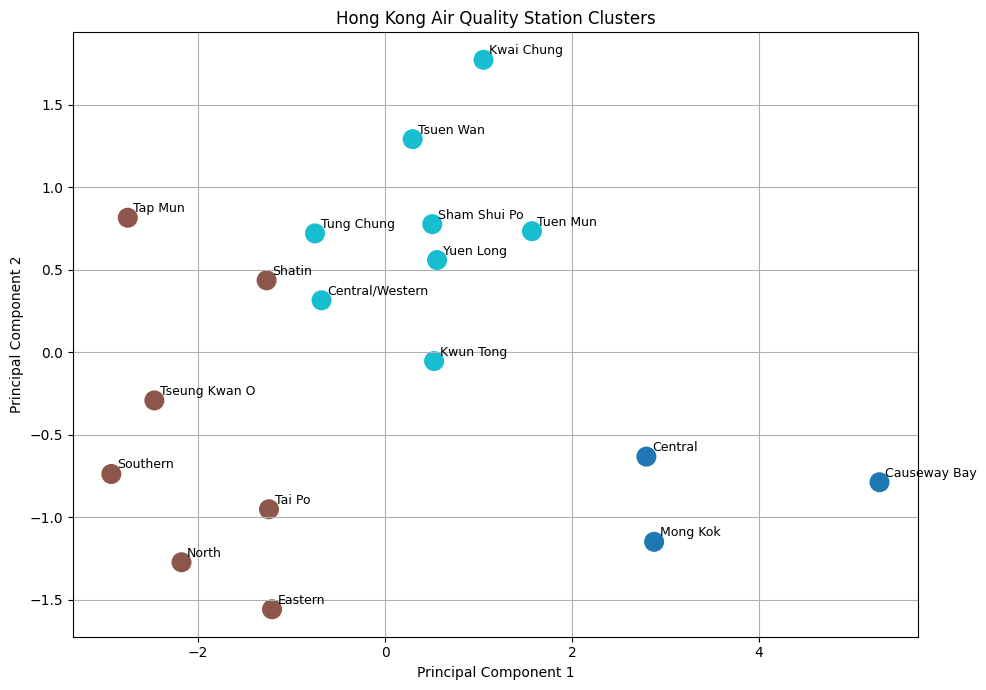


Cluster Characteristics:


,SO2,NOX,NO2,RSP,O3,FSP
cluster,,,,,,
0,5.78,182.91,77.16,36.45,28.47,23.49
1,4.21,41.46,27.91,27.11,62.77,16.14
2,6.83,66.85,43.78,31.60,47.40,19.57


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ==========================================================
# Load Dataset
# ==========================================================

df = pd.read_parquet("pollution_clean_long.parquet")

# ==========================================================
# Candidate pollutants
# ==========================================================

pollutants = [
    "SO2",
    "NOX",
    "NO2",
    "CO",
    "RSP",
    "O3",
    "FSP"
]

# ==========================================================
# Build station feature matrix
# ==========================================================

station_features = (
    df.groupby("station")[pollutants]
      .mean()
)

print("Raw station feature matrix:")
display(station_features)

print("\nMissing values per pollutant:")
print(station_features.isna().sum())

# ==========================================================
# Remove problematic columns
# ==========================================================

missing_rate = (
    station_features.isna()
    .mean()
)

print("\nMissing rate:")
print(missing_rate)

# Drop columns with more than 20% station-level missingness
keep_cols = missing_rate[missing_rate < 0.20].index.tolist()

station_features = station_features[keep_cols]

print("\nColumns kept:")
print(keep_cols)

# Fill any tiny remaining gaps with column means
station_features = station_features.fillna(
    station_features.mean()
)

print("\nRemaining missing values:")
print(station_features.isna().sum().sum())

# ==========================================================
# Standardize
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    station_features
)

# ==========================================================
# Elbow Method
# ==========================================================

inertias = []

for k in range(1, 9):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    km.fit(X_scaled)

    inertias.append(km.inertia_)

plt.figure(figsize=(7,5))

plt.plot(
    range(1, 9),
    inertias,
    marker="o"
)

plt.title("Elbow Method for Station Clustering")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid(True)

plt.show()

# ==========================================================
# Choose K
# ==========================================================

K = 3

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=20
)

clusters = kmeans.fit_predict(X_scaled)

station_features["cluster"] = clusters

print("\nStation clusters:")
display(
    station_features.sort_values("cluster")
)

# ==========================================================
# PCA Visualization
# ==========================================================

pca = PCA(n_components=2)

coords = pca.fit_transform(
    X_scaled
)

plot_df = pd.DataFrame({
    "station": station_features.index,
    "cluster": clusters,
    "PC1": coords[:, 0],
    "PC2": coords[:, 1]
})

plt.figure(figsize=(10,7))

plt.scatter(
    plot_df["PC1"],
    plot_df["PC2"],
    c=plot_df["cluster"],
    cmap="tab10",
    s=180
)

for _, row in plot_df.iterrows():

    plt.annotate(
        row["station"],
        (row["PC1"], row["PC2"]),
        fontsize=9,
        xytext=(4,4),
        textcoords="offset points"
    )

plt.title("Hong Kong Air Quality Station Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Cluster Summary
# ==========================================================

cluster_summary = (
    station_features
    .groupby("cluster")
    .mean()
    .round(2)
)

print("\nCluster Characteristics:")
display(cluster_summary)

Total Tasks: 126

Workers = 1


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    2.8s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    4.2s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    5.6s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    6.9s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   6 out of   6 | elapsed:    8.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   7 out of   7 | elapsed:    9.7s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   8 out of   8 | elapsed:   11.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   9 out of   9 | elapsed:   12.5s remaining:    0.0s



Completed 126 tasks in 151.71 seconds

Workers = 2


[Parallel(n_jobs=1)]: Done 126 out of 126 | elapsed:  2.5min finished
[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    1.5s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    3.3s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    6.5s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    9.9s
/opt/anaconda3/lib/python3.8/site-packages/joblib/externals/loky/process_executor.py:688: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:   13.7s
[Parallel(n_jobs=2)]: Done  28 tasks      | elapsed:   16.9s
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:   21.9s
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:   26.6s
[Parallel(n_jobs=2)]: Done  57 tasks      | elapsed:   31.2s
[Parallel(n_jobs=2)]: Done  68 tasks      | elapsed:   


Completed 126 tasks in 68.22 seconds

Workers = 4


[Parallel(n_jobs=2)]: Done 126 out of 126 | elapsed:  1.1min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    3.2s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    5.0s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    6.8s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    9.5s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:   12.4s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   15.6s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   18.2s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   21.8s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:   24.7s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:   28.6s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:   34.0s



Completed 126 tasks in 41.66 seconds

Workers = 8


[Parallel(n_jobs=4)]: Done 126 out of 126 | elapsed:   41.6s finished
[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    4.8s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    5.6s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    7.7s
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:   10.1s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:   12.8s
[Parallel(n_jobs=8)]: Done  56 tasks      | elapsed:   14.5s
[Parallel(n_jobs=8)]: Done  69 tasks      | elapsed:   17.9s
[Parallel(n_jobs=8)]: Done  82 tasks      | elapsed:   21.1s
[Parallel(n_jobs=8)]: Done  97 tasks      | elapsed:   23.9s



Completed 126 tasks in 31.64 seconds


[Parallel(n_jobs=8)]: Done 124 out of 126 | elapsed:   31.5s remaining:    0.5s
[Parallel(n_jobs=8)]: Done 126 out of 126 | elapsed:   31.6s finished


,Workers,Runtime (s),Speedup
0,1,151.707335,1.000000
1,2,68.221593,2.223744
2,4,41.663085,3.641289
3,8,31.638153,4.795076


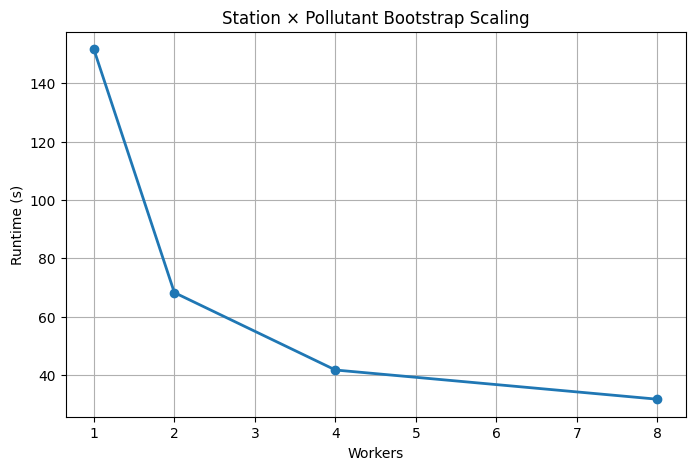

In [27]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

# ==================================================
# Load
# ==================================================

df = pd.read_parquet("pollution_clean_long.parquet")

pollutants = [
    "SO2",
    "NOX",
    "NO2",
    "CO",
    "RSP",
    "O3",
    "FSP"
]

stations = sorted(df["station"].dropna().unique())

# ==================================================
# Pre-split data once
# ==================================================

station_data = {}

for station in stations:

    station_data[station] = {}

    sub = df[df["station"] == station]

    for pollutant in pollutants:

        vals = sub[pollutant].dropna().values

        if len(vals) > 0:
            station_data[station][pollutant] = vals

# ==================================================
# Task
# ==================================================

def bootstrap_station_pollutant(
    station,
    pollutant,
    n_boot=2000
):

    vals = station_data[station].get(pollutant)

    if vals is None:
        return None

    rng = np.random.default_rng(42)

    boot_means = np.empty(n_boot)

    n = len(vals)

    for i in range(n_boot):

        boot_means[i] = rng.choice(
            vals,
            size=n,
            replace=True
        ).mean()

    return boot_means.mean()

# ==================================================
# All Tasks
# ==================================================

tasks = [
    (s, p)
    for s in stations
    for p in pollutants
]

print(f"Total Tasks: {len(tasks)}")

# ==================================================
# Benchmark
# ==================================================

worker_configs = [1,2,4,8]

runtime_list = []

for workers in worker_configs:

    print("\n" + "="*50)
    print(f"Workers = {workers}")
    print("="*50)

    start = time.perf_counter()

    results = Parallel(
        n_jobs=workers,
        verbose=10     # simple built-in progress
    )(
        delayed(
            bootstrap_station_pollutant
        )(
            station,
            pollutant
        )
        for station, pollutant in tasks
    )

    elapsed = time.perf_counter() - start

    runtime_list.append(elapsed)

    print(
        f"\nCompleted {len(tasks)} tasks "
        f"in {elapsed:.2f} seconds"
    )

# ==================================================
# Results
# ==================================================

benchmark_df = pd.DataFrame({
    "Workers": worker_configs,
    "Runtime (s)": runtime_list
})

baseline = benchmark_df.iloc[0]["Runtime (s)"]

benchmark_df["Speedup"] = (
    baseline /
    benchmark_df["Runtime (s)"]
)

display(benchmark_df)

# ==================================================
# Scaling Plot
# ==================================================

plt.figure(figsize=(8,5))

plt.plot(
    benchmark_df["Workers"],
    benchmark_df["Runtime (s)"],
    marker="o",
    linewidth=2
)

plt.title(
    "Station × Pollutant Bootstrap Scaling"
)

plt.xlabel("Workers")
plt.ylabel("Runtime (s)")

plt.grid(True)

plt.show()


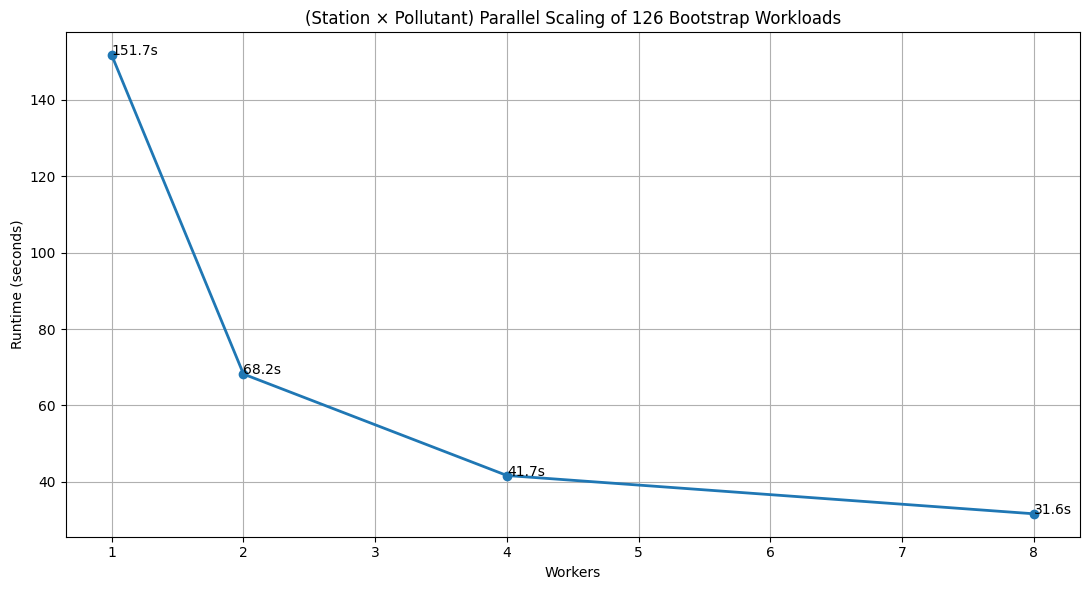


Speedup Table


,Workers,Runtime (s),Speedup
0,1,151.707335,1.000000
1,2,68.221593,2.223744
2,4,41.663085,3.641289
3,8,31.638153,4.795076


In [29]:
plt.figure(figsize=(11,6))

plt.plot(
    benchmark_df["Workers"],
    benchmark_df["Runtime (s)"],
    marker="o",
    linewidth=2,
    label="Runtime"
)

for x, y in zip(
    benchmark_df["Workers"],
    benchmark_df["Runtime (s)"]
):
    plt.text(
        x,
        y,
        f"{y:.1f}s"
    )

plt.title(
    "(Station × Pollutant) Parallel Scaling of 126 Bootstrap Workloads"
)

plt.xlabel("Workers")
plt.ylabel("Runtime (seconds)")

plt.grid(True)

plt.tight_layout()

plt.show()

print("\nSpeedup Table")
display(benchmark_df)

Unlike the earlier AQHI bootstrap experiment, which operated on a single environmental indicator, this experiment expanded the workload to all monitoring stations and all measured pollutants. Each station\-pollutant combination was treated as an independent bootstrap task. For every task, thousands of bootstrap resamples were generated from the historical hourly observations and the mean pollutant concentration was repeatedly recalculated.

With 18 monitoring stations and 7 pollutant variables, a total of 126 independent bootstrap jobs were created. Because each task could execute independently without communication between workers, the workload exhibits an embarrassingly parallel structure. This provides an effective benchmark for evaluating task\-level scalability on a substantially larger environmental dataset.

The results show that increasing the number of worker processes significantly reduced execution time. Runtime decreased from approximately 152 seconds using a single worker to approximately 32 seconds using eight workers, demonstrating effective utilization of multicore processing for large\-scale environmental resampling tasks.

Simple answer:

Bootstrap is a resampling technique used to estimate the stability and uncertainty of a statistic when the underlying population distribution is unknown.

Then immediately connect it to your data:

In our case, we have hourly pollution measurements collected over more than ten years. Rather than relying on a single calculated mean concentration, bootstrap repeatedly resamples the observations and recomputes the mean. This allows us to evaluate how sensitive the estimated pollutant level is to sampling variation

